# *Credit Card Default Classification*

**Dataset:** UCI Default of Credit Card Clients (Taiwan, April - September 2005)  
**Task:** Binary classification - predict whether a cardholder will default on the next payment.  
**Target:** `default.payment.next.month` (1 = default, 0 = paid)  
**Models:** Logistic Regression, KNN, Decision Tree, Random Forest, Gradient Boosting, XGBoost and AdaBoost.  
**No pipeline:** cleaning, feature engineering and scaling are done explicitly, step by step.

### About the dataset
The data contains **30,000 real credit-card accounts** from Taiwan. Every row describes one cardholder just before the next payment is due: who they are (credit limit, age, gender, education, marital status), whether they paid on time in each of the last six months, how much they were billed each month, and how much cash they actually paid back.

Around **22% of the accounts default** and 78% pay on time, so the target is imbalanced. The strongest signal is recent repayment behaviour (`PAY_0`, last month's payment status), more than age or education.

---


In [1]:
import json
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

TARGET = "default.payment.next.month"
RS = 42


In [2]:
df = pd.read_csv("data/UCI_Credit_Card.csv")


--------------
# *Data Inspection*
--------------


In [3]:
df.shape


(30000, 25)


In [4]:
df.head()


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,-2,-2,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,0,2,2682.0,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,0,0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,0,0,46990.0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,0,0,8617.0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [5]:
df.sample(5)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
834,835,20000.0,2,1,2,23,0,0,0,0,0,-2,17246.0,16988.0,15973.0,18773.0,0.0,0.0,2000.0,2000.0,3000.0,0.0,0.0,0.0,0
12574,12575,360000.0,1,1,2,28,-2,-2,-2,-2,-2,-2,14433.0,15157.0,8564.0,1495.0,5977.0,1211.0,2394.0,8606.0,1502.0,6006.0,4217.0,2228.0,0
9845,9846,130000.0,2,3,1,43,0,0,0,0,0,2,74020.0,71527.0,66370.0,43882.0,41063.0,29215.0,5000.0,3000.0,2500.0,4100.0,0.0,5000.0,0
9265,9266,60000.0,2,1,2,23,0,0,0,0,0,0,17191.0,17864.0,18408.0,18393.0,18238.0,18345.0,1700.0,1600.0,1000.0,1000.0,1000.0,2000.0,0
4111,4112,280000.0,2,2,1,45,1,-2,-1,-1,-2,-2,0.0,0.0,3288.0,0.0,0.0,0.0,0.0,3288.0,0.0,0.0,0.0,2942.0,0


In [6]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   30000 non-null

In [7]:
df.describe()


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,-0.266200,-0.291100,51223.330900,49179.075167,4.701315e+04,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,1.133187,1.149988,73635.860576,71173.768783,6.934939e+04,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,-165580.000000,-69777.000000,-1.572640e+05,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,3558.750000,2984.750000,2.666250e+03,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,22381.500000,21200.000000,2.008850e+04,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,67091.000000,64006.250000,6.016475e+04,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000,964511.000000,983931.000000,1.664089e+06,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [8]:
df.isnull().sum()


ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default.payment.next.month    0
dtype: int64


In [9]:
# missing percentage per column (only columns which actually have missing values)
def missing_per(column):
    null_count = df[column].isnull().sum()
    return round((null_count / df.shape[0]) * 100, 2)

for col in df.columns:
    if df[col].isnull().sum() > 0:
        print(f"{col} -> {missing_per(col)}%")

print("Total missing values:", df.isnull().sum().sum())


Total missing values: 0


In [10]:
df.duplicated().sum()


np.int64(0)


In [11]:
print("Target value counts (0 = paid, 1 = default):")
print(df[TARGET].value_counts())
print("\nDefault rate:", round(df[TARGET].mean() * 100, 2), "%")


Target value counts (0 = paid, 1 = default):
default.payment.next.month
0    23364
1     6636
Name: count, dtype: int64

Default rate: 22.12 %


In [12]:
print("SEX (1 = male, 2 = female):")
print(df["SEX"].value_counts())

print("\nEDUCATION (1 = grad, 2 = university, 3 = high school, 4 = other):")
print(df["EDUCATION"].value_counts().sort_index())

print("\nMARRIAGE (1 = married, 2 = single, 3 = other):")
print(df["MARRIAGE"].value_counts().sort_index())


SEX (1 = male, 2 = female):
SEX
2    18112
1    11888
Name: count, dtype: int64

EDUCATION (1 = grad, 2 = university, 3 = high school, 4 = other):
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

MARRIAGE (1 = married, 2 = single, 3 = other):
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64


In [13]:
print("PAY_0 - repayment status last month:")
print(df["PAY_0"].value_counts().sort_index())


PAY_0 - repayment status last month:
PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64


### Dataset overview:
* **Shape:** 30,000 rows x 25 columns
* **Target:** `default.payment.next.month` -> 23,364 paid (77.88%) vs 6,636 default (22.12%) -> **imbalanced**
* **Missing values:** exactly 0 in every column
* **Duplicates:** 35 duplicate rows found
* **ID column:** a unique client identifier with no predictive meaning -> drop it
* **Undocumented codes:** `EDUCATION` has 0, 5 and 6; `MARRIAGE` has 0 -> fold into `Other`
* **Strongest signal:** recent repayment status (`PAY_0`), where positive values mean months late


--------------
## **User_defined Functions**
--------------


In [14]:
# Outlier detection with the IQR rule
def outlier_detection(column_name):
    q1 = df[column_name].quantile(0.25)
    q3 = df[column_name].quantile(0.75)
    iqr = q3 - q1

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    outliers = df[column_name][
        (df[column_name] < lower_limit) | (df[column_name] > upper_limit)
    ]
    return outliers.tolist()

numerical_cols = [
    "LIMIT_BAL", "AGE",
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3",
    "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3",
    "PAY_AMT4", "PAY_AMT5", "PAY_AMT6",
]

outlier_table = pd.DataFrame({
    "outlier_rows": [len(outlier_detection(c)) for c in numerical_cols],
    "outlier_percentage": [
        round(len(outlier_detection(c)) / len(df) * 100, 2) for c in numerical_cols
    ],
}, index=numerical_cols)

outlier_table


,outlier_rows,outlier_percentage
LIMIT_BAL,167,0.56
AGE,272,0.91
BILL_AMT1,2400,8.00
BILL_AMT2,2395,7.98
BILL_AMT3,2469,8.23
BILL_AMT4,2622,8.74
BILL_AMT5,2725,9.08
BILL_AMT6,2693,8.98
PAY_AMT1,2745,9.15
PAY_AMT2,2714,9.05


### Outlier note:
* `LIMIT_BAL` and the bill/payment columns have many statistical outliers.
* These are **real high-value bank accounts**, not measurement errors, so they are kept.
* The models used here are tree-based or regularized linear models, which handle this better than distance-only methods.


--------------
# *Data Cleaning*
--------------


In [15]:
df = df.drop(columns=["ID"])


### *"ID"* column is deleted because it has all unique values and no predictive signal.


In [16]:
# Fix undocumented category codes
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})


### *Undocumented categories replaced:*
* `EDUCATION`: 0, 5, 6 -> 4 (`Other`)
* `MARRIAGE`: 0 -> 3 (`Other`)


In [17]:
print("Duplicates before:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicates after :", df.duplicated().sum())
print("Cleaned shape    :", df.shape)


Duplicates before: 35
Duplicates after : 0
Cleaned shape    : (29965, 24)


In [18]:
print("Missing values:", df.isnull().sum().sum())
print("EDUCATION:", sorted(df["EDUCATION"].unique()))
print("MARRIAGE :", sorted(df["MARRIAGE"].unique()))
df.head()


Missing values: 0
EDUCATION: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
MARRIAGE : [np.int64(1), np.int64(2), np.int64(3)]


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,20000.0,2,2,1,24,2,2,-1,-1,-2,-2,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,120000.0,2,2,2,26,-1,2,0,0,0,2,2682.0,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,90000.0,2,2,2,34,0,0,0,0,0,0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,50000.0,2,2,1,37,0,0,0,0,0,0,46990.0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,50000.0,1,2,1,57,-1,0,-1,0,0,0,8617.0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


--------------
# *Exploratory Data Analysis*
--------------


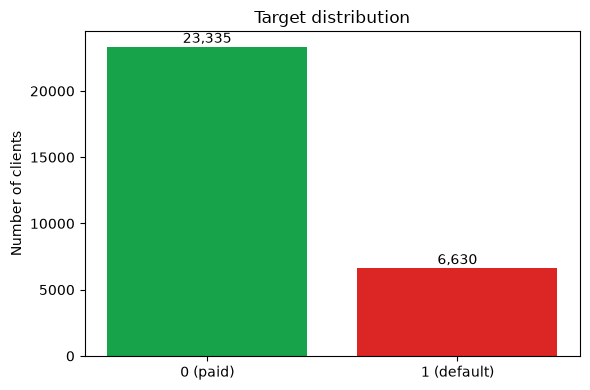

In [19]:
# Target distribution
vc = df[TARGET].value_counts().sort_index()
plt.figure(figsize=(6, 4))
bars = plt.bar(["0 (paid)", "1 (default)"], vc.values, color=["#16a34a", "#dc2626"])
plt.title("Target distribution")
plt.ylabel("Number of clients")
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 300,
             f"{int(bar.get_height()):,}", ha="center")
plt.tight_layout()
plt.show()


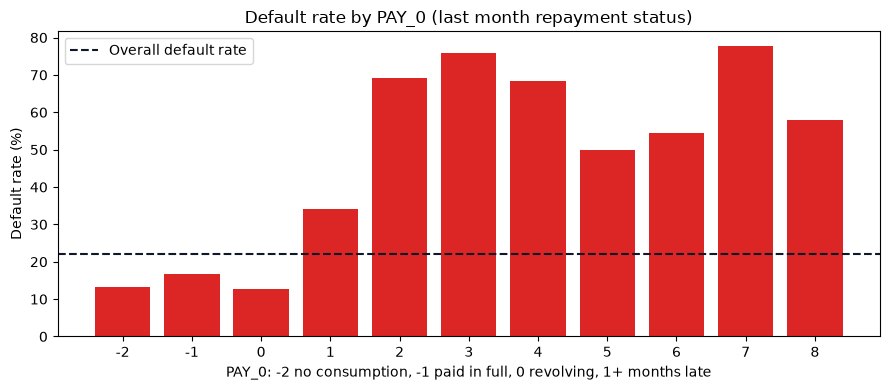

In [20]:
# Default rate by repayment status (PAY_0 is the most important feature)
pay_rate = df.groupby("PAY_0")[TARGET].mean() * 100

plt.figure(figsize=(9, 4))
bars = plt.bar([str(i) for i in pay_rate.index], pay_rate.values, color="#dc2626")
plt.title("Default rate by PAY_0 (last month repayment status)")
plt.xlabel("PAY_0: -2 no consumption, -1 paid in full, 0 revolving, 1+ months late")
plt.ylabel("Default rate (%)")
plt.axhline(df[TARGET].mean() * 100, color="#0f172a", linestyle="--",
            label="Overall default rate")
plt.legend()
plt.tight_layout()
plt.show()


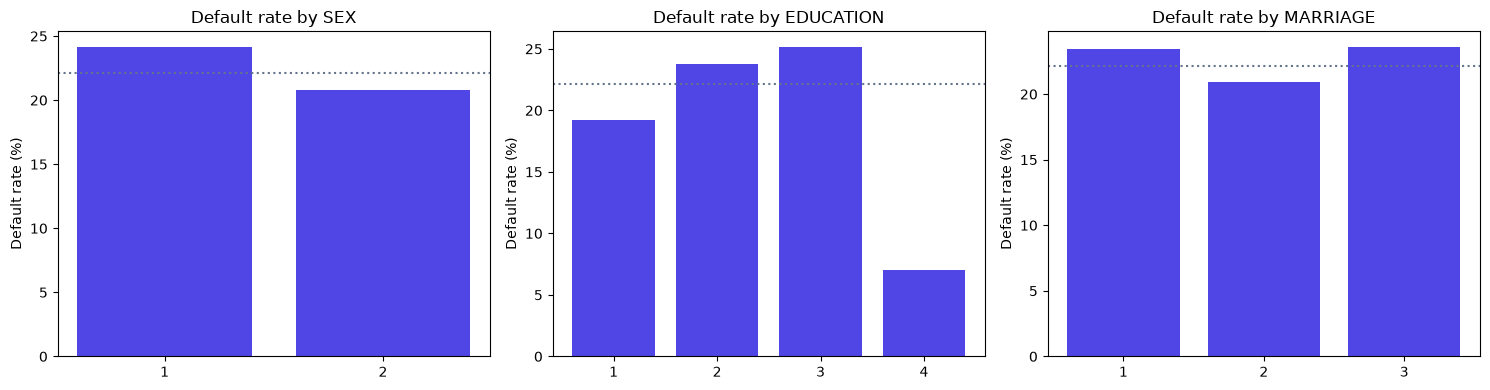

In [21]:
# Default rate across demographics
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["SEX", "EDUCATION", "MARRIAGE"]):
    rate = df.groupby(col)[TARGET].mean() * 100
    ax.bar(rate.index.astype(str), rate.values, color="#4f46e5")
    ax.set_title(f"Default rate by {col}")
    ax.set_ylabel("Default rate (%)")
    ax.axhline(df[TARGET].mean() * 100, color="#64748b", linestyle=":")
plt.tight_layout()
plt.show()


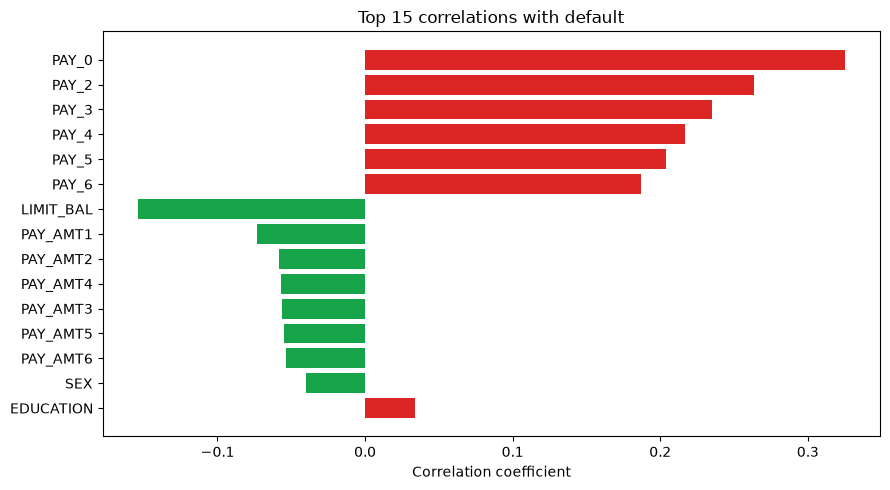

,correlation
PAY_0,0.325
PAY_2,0.264
PAY_3,0.235
PAY_4,0.217
PAY_5,0.204
PAY_6,0.187
LIMIT_BAL,-0.154
PAY_AMT1,-0.073
PAY_AMT2,-0.059
PAY_AMT4,-0.057


In [22]:
# Correlation of every raw feature with the target
corr = df.corr()[TARGET].drop(TARGET)
top_corr = corr.reindex(corr.abs().sort_values(ascending=False).index).head(15)

plt.figure(figsize=(9, 5))
colors = ["#dc2626" if value > 0 else "#16a34a" for value in top_corr.values]
plt.barh([str(c) for c in top_corr.index[::-1]], top_corr.values[::-1],
         color=colors[::-1])
plt.title("Top 15 correlations with default")
plt.xlabel("Correlation coefficient")
plt.tight_layout()
plt.show()

top_corr.round(3).to_frame("correlation")


### EDA insights:
* Recent repayment behaviour is the dominant signal: default rate jumps sharply once `PAY_0` is 1 or more.
* Demographics (sex, education, marriage) show only small differences.
* Credit limit and bill amounts have a weaker but useful relationship with default.
* The target is imbalanced (22.1% default), so models are compared with **precision, recall and F1** as well as accuracy.


--------------
# *Feature Engineering*
#### Six simple financial ratios, no pipeline
--------------


In [23]:
PAY_COLS   = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
BILL_COLS  = [f"BILL_AMT{i}" for i in range(1, 7)]
PAYAM_COLS = [f"PAY_AMT{i}" for i in range(1, 7)]

DEMO_COLS = ["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE"]
RAW_FEATURES = DEMO_COLS + PAY_COLS + BILL_COLS + PAYAM_COLS

ENGINEERED_FEATURES = [
    "credit_utilization",
    "avg_utilization_6m",
    "late_months",
    "max_delay_months",
    "payment_to_bill_ratio",
    "bill_trend_6m",
]
FEATURES = RAW_FEATURES + ENGINEERED_FEATURES


def build_features(frame):
    # Create the same 29 model columns used by train.py and app.py.
    X = frame[RAW_FEATURES].astype(float).copy()
    limit = X["LIMIT_BAL"].replace(0, np.nan)

    X["credit_utilization"] = (X["BILL_AMT1"] / limit).fillna(0.0)
    X["avg_utilization_6m"] = (X[BILL_COLS].mean(axis=1) / limit).fillna(0.0)
    X["late_months"] = (X[PAY_COLS] > 0).sum(axis=1).astype(float)
    X["max_delay_months"] = X[PAY_COLS].max(axis=1).astype(float)
    X["payment_to_bill_ratio"] = (
        X["PAY_AMT1"] / (X["BILL_AMT1"].abs() + 1.0)
    ).clip(0.0, 20.0)
    X["bill_trend_6m"] = (X["BILL_AMT1"] - X["BILL_AMT6"]).astype(float)

    return X[FEATURES]


feature_df = build_features(df)
feature_df.head()


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,credit_utilization,avg_utilization_6m,late_months,max_delay_months,payment_to_bill_ratio,bill_trend_6m
0,20000.0,2.0,2.0,1.0,24.0,2.0,2.0,-1.0,-1.0,-2.0,-2.0,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,0.195650,0.064200,2.0,2.0,0.000000,3913.0
1,120000.0,2.0,2.0,2.0,26.0,-1.0,2.0,0.0,0.0,0.0,2.0,2682.0,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,0.022350,0.023718,2.0,2.0,0.000000,-579.0
2,90000.0,2.0,2.0,2.0,34.0,0.0,0.0,0.0,0.0,0.0,0.0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0.324878,0.188246,0.0,0.0,0.051915,13690.0
3,50000.0,2.0,2.0,1.0,37.0,0.0,0.0,0.0,0.0,0.0,0.0,46990.0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0.939800,0.771113,0.0,0.0,0.042561,17443.0
4,50000.0,1.0,2.0,1.0,57.0,-1.0,0.0,-1.0,0.0,0.0,0.0,8617.0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0.172340,0.364463,0.0,0.0,0.232072,-10514.0


In [24]:
# Do the engineered features separate payers from defaulters?
check = pd.DataFrame({
    "paid_mean": feature_df[df[TARGET] == 0][ENGINEERED_FEATURES].mean(),
    "default_mean": feature_df[df[TARGET] == 1][ENGINEERED_FEATURES].mean(),
})
check["difference"] = check["default_mean"] - check["paid_mean"]
check.round(3)


,paid_mean,default_mean,difference
credit_utilization,0.405,0.491,0.085
avg_utilization_6m,0.352,0.450,0.098
late_months,0.504,1.996,1.492
max_delay_months,0.202,1.275,1.073
payment_to_bill_ratio,1.233,0.838,-0.395
bill_trend_6m,12968.055,10246.992,-2721.063


### What the new features mean:
* `credit_utilization` - how much of the credit limit is currently used
* `avg_utilization_6m` - persistent usage over six months
* `late_months` - how many of the last six months had a payment delay
* `max_delay_months` - worst delay in the window
* `payment_to_bill_ratio` - whether the customer actually pays the statement
* `bill_trend_6m` - is the outstanding debt growing?


--------------
# *Data Preprocessing*
#### Split, then fit StandardScaler directly on the training data (NO PIPELINE)
--------------


In [25]:
X = feature_df
y = df[TARGET].astype(int)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Default rate:", round(y.mean() * 100, 2), "%")


X shape: (29965, 29)
y shape: (29965,)
Default rate: 22.13 %


In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RS, stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("Train default rate:", round(y_train.mean() * 100, 2), "%")
print("Test  default rate:", round(y_test.mean() * 100, 2), "%")


X_train: (23972, 29)
X_test : (5993, 29)
Train default rate: 22.13 %
Test  default rate: 22.13 %


In [27]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled train shape:", X_train_scaled.shape)
print("Scaled test shape :", X_test_scaled.shape)
X_train_scaled[:3]


Scaled train shape: (23972, 29)
Scaled test shape : (5993, 29)


array([[ 1.02202404, -1.22974045,  0.21588886, -1.07045295, -0.05026409,
        -1.77194733, -1.5664941 , -1.54426568, -1.53003683, -1.53879369,
        -1.49253378, -0.70003029, -0.6944637 , -0.67853094, -0.67405704,
        -0.66508491, -0.65293829, -0.3388458 , -0.24568495, -0.2949728 ,
        -0.32089199, -0.31868422, -0.28931899, -1.03185872, -1.06266327,
        -0.53697224, -1.82027193, -0.30070092, -0.28442573],
       [-0.90301995,  0.81317972,  1.5615175 ,  2.7603895 ,  0.16721283,
         1.79373829,  1.78105746,  1.81835916,  1.90681127,  2.01025861,
         2.00501208, -0.04907897, -0.00558153,  0.03211511,  0.07232423,
        -0.22008392, -0.20896773, -0.20095992, -0.18357769, -0.2949728 ,
        -0.09393818, -0.31868422, -0.2233757 ,  1.27982545,  1.27582936,
         3.33071221,  1.1638151 , -0.2880969 ,  0.20358417],
       [-0.67201467, -1.22974045, -1.12973978,  0.84496827, -1.35512562,
        -0.88052592, -0.72960621, -0.70360947, -0.67082481,  0.23573246,
  

### Important:
* The scaler is fitted **only on `X_train`** and then applied to `X_test`.
* There is no `Pipeline` object anywhere in this notebook.
* Scale-sensitive models use `X_train_scaled`; tree models use the raw `X_train.values`.


--------------
# *Data Modelling*
#### Simple hyperparameters with GridSearchCV + 3-fold StratifiedKFold, scored by accuracy
--------------


In [28]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
)
from xgboost import XGBClassifier

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RS)

results = {}
fitted_models = {}
test_predictions = {}
test_probabilities = {}


def tune_and_evaluate(name, estimator, param_grid, needs_scaling=False):
    # Run GridSearchCV, evaluate on the untouched test set, store the result.
    X_tr = X_train_scaled if needs_scaling else X_train.values
    X_te = X_test_scaled if needs_scaling else X_test.values

    search = GridSearchCV(
        estimator=estimator,
        param_grid=param_grid,
        scoring="accuracy",
        cv=cv,
        n_jobs=1,
        refit=True,
        verbose=0,
    )
    search.fit(X_tr, y_train)
    model = search.best_estimator_

    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1]

    results[name] = {
        "best_params": search.best_params_,
        "cv_accuracy": round(float(search.best_score_), 4),
        "train_accuracy": round(float(model.score(X_tr, y_train)), 4),
        "test_accuracy": round(float(accuracy_score(y_test, y_pred)), 4),
        "precision": round(float(precision_score(y_test, y_pred, zero_division=0)), 4),
        "recall": round(float(recall_score(y_test, y_pred, zero_division=0)), 4),
        "f1": round(float(f1_score(y_test, y_pred, zero_division=0)), 4),
        "confusion_matrix": confusion_matrix(y_test, y_pred).tolist(),
    }
    fitted_models[name] = model
    test_predictions[name] = y_pred
    test_probabilities[name] = y_prob

    print(f"Best params : {search.best_params_}")
    print(f"CV accuracy : {search.best_score_:.4f}")
    print(f"Test accuracy: {results[name]['test_accuracy']:.4f}")
    print(f"Precision / Recall / F1: "
          f"{results[name]['precision']:.4f} / "
          f"{results[name]['recall']:.4f} / "
          f"{results[name]['f1']:.4f}")
    print("Confusion matrix:")
    print(np.array(results[name]["confusion_matrix"]))

    return search


### Model 1 - Logistic Regression (scaled features)


In [29]:
lr_search = tune_and_evaluate(
    "Logistic Regression",
    LogisticRegression(max_iter=2000, random_state=RS),
    {
        "C": [0.1, 1.0, 10.0],
    },
    needs_scaling=True,
)
lr_search.best_params_


Best params : {'C': 0.1}
CV accuracy : 0.8065
Test accuracy: 0.8101
Precision / Recall / F1: 0.6572 / 0.2964 / 0.4085
Confusion matrix:
[[4462  205]
 [ 933  393]]


{'C': 0.1}


### Model 2 - KNN (scaled features)
#### First check the elbow: accuracy vs number of neighbours


Best k in this sweep: 29


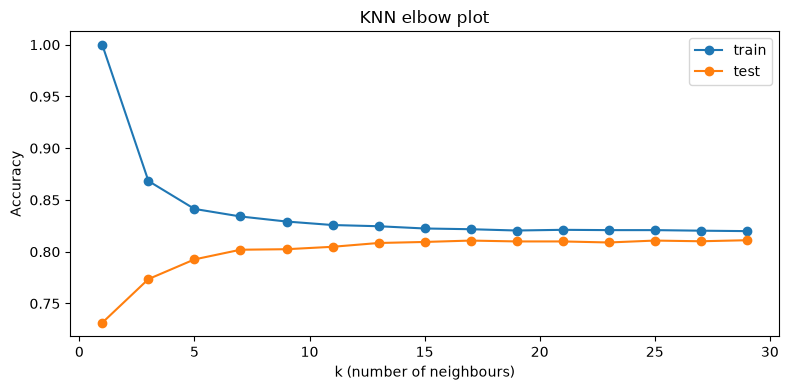

In [30]:
k_values = list(range(1, 31, 2))
train_scores, test_scores = [], []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    train_scores.append(knn.score(X_train_scaled, y_train))
    test_scores.append(knn.score(X_test_scaled, y_test))

plt.figure(figsize=(8, 4))
plt.plot(k_values, train_scores, marker="o", label="train")
plt.plot(k_values, test_scores, marker="o", label="test")
plt.xlabel("k (number of neighbours)")
plt.ylabel("Accuracy")
plt.title("KNN elbow plot")
plt.legend()
plt.tight_layout()
plt.show()

print("Best k in this sweep:", k_values[int(np.argmax(test_scores))])


In [31]:
knn_search = tune_and_evaluate(
    "KNN",
    KNeighborsClassifier(),
    {
        "n_neighbors": [15, 25, 35],
    },
    needs_scaling=True,
)
knn_search.best_params_


Best params : {'n_neighbors': 25}
CV accuracy : 0.8114
Test accuracy: 0.8108
Precision / Recall / F1: 0.6333 / 0.3439 / 0.4457
Confusion matrix:
[[4403  264]
 [ 870  456]]


{'n_neighbors': 25}


### Model 3 - Decision Tree (raw features)
#### First check max_depth with a train vs test curve to see overfitting


Best depth in this sweep: 4


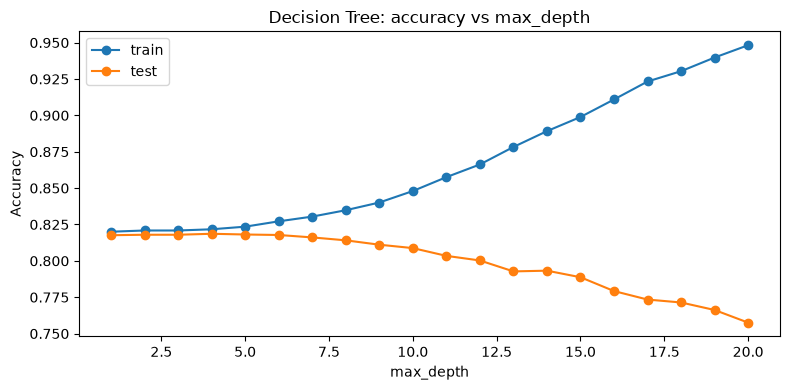

In [32]:
depths = list(range(1, 21))
train_scores, test_scores = [], []

for depth in depths:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=RS)
    tree.fit(X_train.values, y_train)
    train_scores.append(tree.score(X_train.values, y_train))
    test_scores.append(tree.score(X_test.values, y_test))

plt.figure(figsize=(8, 4))
plt.plot(depths, train_scores, marker="o", label="train")
plt.plot(depths, test_scores, marker="o", label="test")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree: accuracy vs max_depth")
plt.legend()
plt.tight_layout()
plt.show()

print("Best depth in this sweep:", depths[int(np.argmax(test_scores))])


In [33]:
dt_search = tune_and_evaluate(
    "Decision Tree",
    DecisionTreeClassifier(random_state=RS),
    {
        "max_depth": [4, 6, 8],
    },
    needs_scaling=False,
)
dt_search.best_params_


Best params : {'max_depth': 4}
CV accuracy : 0.8202
Test accuracy: 0.8186
Precision / Recall / F1: 0.7029 / 0.3122 / 0.4324
Confusion matrix:
[[4492  175]
 [ 912  414]]


{'max_depth': 4}


### Model 4 - Random Forest (raw features)


In [34]:
rf_search = tune_and_evaluate(
    "Random Forest",
    RandomForestClassifier(n_estimators=100, random_state=RS, n_jobs=1),
    {
        "max_depth": [8, 12],
    },
    needs_scaling=False,
)
rf_search.best_params_


Best params : {'max_depth': 8}
CV accuracy : 0.8203
Test accuracy: 0.8190
Precision / Recall / F1: 0.6685 / 0.3605 / 0.4684
Confusion matrix:
[[4430  237]
 [ 848  478]]


{'max_depth': 8}


### Model 5 - Gradient Boosting (raw features)


In [35]:
gb_search = tune_and_evaluate(
    "Gradient Boosting",
    GradientBoostingClassifier(random_state=RS),
    {
        "n_estimators": [100],
        "learning_rate": [0.05, 0.1],
    },
    needs_scaling=False,
)
gb_search.best_params_


Best params : {'learning_rate': 0.1, 'n_estimators': 100}
CV accuracy : 0.8215
Test accuracy: 0.8188
Precision / Recall / F1: 0.6709 / 0.3552 / 0.4645
Confusion matrix:
[[4436  231]
 [ 855  471]]


{'learning_rate': 0.1, 'n_estimators': 100}


### Model 6 - XGBoost (raw features)


In [36]:
xgb_search = tune_and_evaluate(
    "XGBoost",
    XGBClassifier(
        n_estimators=200,
        eval_metric="logloss",
        tree_method="hist",
        random_state=RS,
        n_jobs=1,
    ),
    {
        "max_depth": [4, 6],
        "learning_rate": [0.05, 0.1],
    },
    needs_scaling=False,
)
xgb_search.best_params_


Best params : {'learning_rate': 0.05, 'max_depth': 4}
CV accuracy : 0.8207
Test accuracy: 0.8203
Precision / Recall / F1: 0.6766 / 0.3597 / 0.4697
Confusion matrix:
[[4439  228]
 [ 849  477]]


{'learning_rate': 0.05, 'max_depth': 4}


### Model 7 - AdaBoost (raw features)


In [37]:
ada_search = tune_and_evaluate(
    "AdaBoost",
    AdaBoostClassifier(random_state=RS),
    {
        "n_estimators": [100, 200],
    },
    needs_scaling=False,
)
ada_search.best_params_


Best params : {'n_estimators': 200}
CV accuracy : 0.8195
Test accuracy: 0.8151
Precision / Recall / F1: 0.6703 / 0.3235 / 0.4364
Confusion matrix:
[[4456  211]
 [ 897  429]]


{'n_estimators': 200}


--------------
# *Model Comparison*
--------------


In [38]:
comparison = pd.DataFrame([
    {
        "Model": name,
        "Train accuracy": info["train_accuracy"],
        "Test accuracy": info["test_accuracy"],
        "Precision": info["precision"],
        "Recall": info["recall"],
        "F1": info["f1"],
        "Best params": info["best_params"],
    }
    for name, info in results.items()
]).sort_values("Test accuracy", ascending=False).reset_index(drop=True)

comparison


,Model,Train accuracy,Test accuracy,Precision,Recall,F1,Best params
0,XGBoost,0.8308,0.8203,0.6766,0.3597,0.4697,"{'learning_rate': 0.05, 'max_depth': 4}"
1,Random Forest,0.8382,0.8190,0.6685,0.3605,0.4684,{'max_depth': 8}
2,Gradient Boosting,0.8277,0.8188,0.6709,0.3552,0.4645,"{'learning_rate': 0.1, 'n_estimators': 100}"
3,Decision Tree,0.8217,0.8186,0.7029,0.3122,0.4324,{'max_depth': 4}
4,AdaBoost,0.8195,0.8151,0.6703,0.3235,0.4364,{'n_estimators': 200}
5,KNN,0.8209,0.8108,0.6333,0.3439,0.4457,{'n_neighbors': 25}
6,Logistic Regression,0.8080,0.8101,0.6572,0.2964,0.4085,{'C': 0.1}


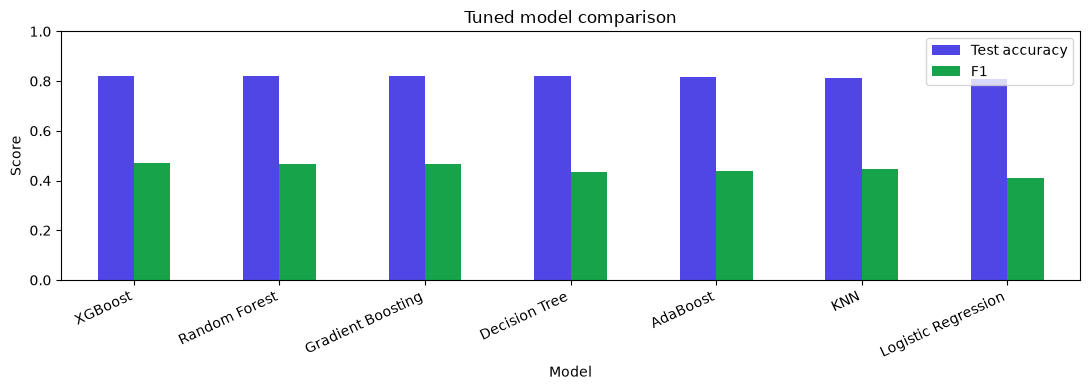

In [39]:
plot_df = comparison.set_index("Model")[["Test accuracy", "F1"]]
plot_df.plot(kind="bar", figsize=(11, 4), color=["#4f46e5", "#16a34a"])
plt.title("Tuned model comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


In [40]:
best_name = comparison.iloc[0]["Model"]
print("Best model (by test accuracy):", best_name)
print(comparison.iloc[0][["Test accuracy", "Precision", "Recall", "F1"]].to_string())


Best model (by test accuracy): XGBoost
Test accuracy    0.8203
Precision        0.6766
Recall           0.3597
F1               0.4697


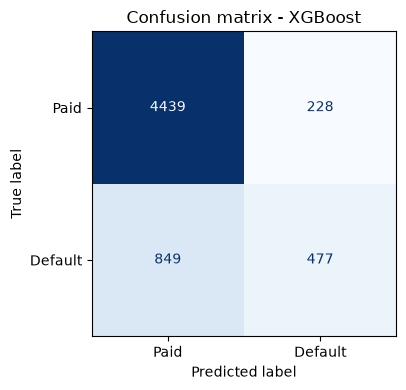

In [41]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions[best_name],
    display_labels=["Paid", "Default"],
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
ax.set_title(f"Confusion matrix - {best_name}")
plt.tight_layout()
plt.show()


### Comparison notes:
* XGBoost, Gradient Boosting and Random Forest are the strongest models.
* All tuned models beat the 22% base rate, but **accuracy alone hides the class imbalance**, so precision, recall and F1 are shown too.
* Test accuracy is used to choose the best model because it is the simplest, most direct measure.
* The final app shows every model's prediction so the result is transparent.


--------------
### *Save every model weight and the scaler for the Streamlit app*
--------------


In [42]:
os.makedirs("models", exist_ok=True)

# Save each tuned model separately
for name, model in fitted_models.items():
    filename = name.replace(" ", "_") + ".joblib"
    joblib.dump(model, os.path.join("models", filename))
    print("saved ->", os.path.join("models", filename))

# Save the best model and the fitted scaler (NO PIPELINE)
joblib.dump(fitted_models[best_name], "models/best_model.joblib")
joblib.dump(scaler, "models/scaler.joblib")
print("saved -> models/best_model.joblib")
print("saved -> models/scaler.joblib")


saved -> models\Logistic_Regression.joblib
saved -> models\KNN.joblib
saved -> models\Decision_Tree.joblib
saved -> models\Random_Forest.joblib
saved -> models\Gradient_Boosting.joblib
saved -> models\XGBoost.joblib
saved -> models\AdaBoost.joblib
saved -> models/best_model.joblib
saved -> models/scaler.joblib


In [43]:
# Evaluation data for charts / reproducibility
eval_data = {
    "y_test": y_test.tolist(),
    "probabilities": {name: prob.tolist() for name, prob in test_probabilities.items()},
    "predictions": {name: pred.tolist() for name, pred in test_predictions.items()},
    "feature_names": FEATURES,
}
joblib.dump(eval_data, "models/eval_data.joblib")
print("saved -> models/eval_data.joblib")


saved -> models/eval_data.joblib


In [44]:
# Full metrics file consumed by app.py
metrics = {
    "trained_at": pd.Timestamp.now().isoformat(timespec="seconds"),
    "dataset": {
        "name": "UCI Default of Credit Card Clients",
        "raw_rows": 30000,
        "rows": int(len(df)),
        "raw_features": 23,
        "engineered_features": 6,
        "model_features": int(len(FEATURES)),
        "default_rate": float(y.mean()),
        "test_rows": int(len(y_test)),
    },
    "selection_metric": "test_accuracy",
    "best_model": best_name,
    "best_model_file": "best_model.joblib",
    "best_needs_scale": best_name in ["Logistic Regression", "KNN"],
    "feature_names": FEATURES,
    "raw_features": RAW_FEATURES,
    "results": {},
}

needs_scaling_map = {
    "Logistic Regression": True,
    "KNN": True,
    "Decision Tree": False,
    "Random Forest": False,
    "Gradient Boosting": False,
    "XGBoost": False,
    "AdaBoost": False,
}

for name, info in results.items():
    metrics["results"][name] = {
        "model_file": name.replace(" ", "_") + ".joblib",
        "needs_scaling": needs_scaling_map[name],
        "best_params": info["best_params"],
        "cv_accuracy": info["cv_accuracy"],
        "train_accuracy": info["train_accuracy"],
        "test_accuracy": info["test_accuracy"],
        "test_precision": info["precision"],
        "test_recall": info["recall"],
        "test_f1": info["f1"],
        "confusion_matrix": info["confusion_matrix"],
    }

with open("models/metrics.json", "w", encoding="utf-8") as handle:
    json.dump(metrics, handle, indent=2, default=float)

print("saved -> models/metrics.json")
print("best model:", best_name)


saved -> models/metrics.json
best model: XGBoost


In [45]:
# Small summary file used by older helper scripts
summary = {
    "random_state": RS,
    "rows": int(len(df)),
    "features": int(len(FEATURES)),
    "best_model": best_name,
    "selection_metric": "Accuracy",
    "models": {
        name: {
            "checked": "GridSearchCV - StratifiedKFold(3) - Accuracy",
            "best": json.dumps(info["best_params"]),
            "train_acc": info["train_accuracy"],
            "test_acc": info["test_accuracy"],
        }
        for name, info in results.items()
    },
}

with open("models/notebook_results.json", "w", encoding="utf-8") as handle:
    json.dump(summary, handle, indent=2, default=float)

print("saved -> models/notebook_results.json")


saved -> models/notebook_results.json


--------------
# *Single-customer inference demo*
#### Exactly the same path the Streamlit app uses
--------------


In [46]:
profile = {
    "LIMIT_BAL": 50000.0,
    "SEX": 1,
    "EDUCATION": 3,
    "MARRIAGE": 2,
    "AGE": 26,
    "PAY_0": 2, "PAY_2": 2, "PAY_3": 1,
    "PAY_4": 0, "PAY_5": 0, "PAY_6": 0,
    "BILL_AMT1": 48500.0, "BILL_AMT2": 47000.0, "BILL_AMT3": 45500.0,
    "BILL_AMT4": 44000.0, "BILL_AMT5": 43000.0, "BILL_AMT6": 42000.0,
    "PAY_AMT1": 0.0, "PAY_AMT2": 0.0, "PAY_AMT3": 500.0,
    "PAY_AMT4": 800.0, "PAY_AMT5": 1000.0, "PAY_AMT6": 1000.0,
}

profile_df = pd.DataFrame([profile])
profile_features = build_features(profile_df)

inference_rows = []
for name, model in fitted_models.items():
    if name in ["Logistic Regression", "KNN"]:
        matrix = scaler.transform(profile_features)
    else:
        matrix = profile_features.values
    probability = model.predict_proba(matrix)[0, 1]
    inference_rows.append({
        "Model": name,
        "Prediction": "Default" if probability >= 0.5 else "Will pay",
        "Default probability": round(float(probability) * 100, 2),
        "Test accuracy": results[name]["test_accuracy"] * 100,
    })

pd.DataFrame(inference_rows).sort_values("Test accuracy", ascending=False).reset_index(drop=True)


,Model,Prediction,Default probability,Test accuracy
0,XGBoost,Default,63.52,82.03
1,Random Forest,Default,59.37,81.90
2,Gradient Boosting,Default,66.55,81.88
3,Decision Tree,Default,67.40,81.86
4,AdaBoost,Default,59.25,81.51
5,KNN,Will pay,44.00,81.08
6,Logistic Regression,Default,54.99,81.01


In [47]:
# Derived indicators for this profile
print("Credit utilization :", round(float(profile_features["credit_utilization"].iloc[0]) * 100, 1), "%")
print("6-month utilization:", round(float(profile_features["avg_utilization_6m"].iloc[0]) * 100, 1), "%")
print("Late months        :", int(profile_features["late_months"].iloc[0]), "/ 6")
print("Worst delay        :", int(profile_features["max_delay_months"].iloc[0]), "months")


Credit utilization : 97.0 %
6-month utilization: 90.0 %
Late months        : 3 / 6
Worst delay        : 2 months


--------------
# *Conclusion*
--------------
* The UCI credit-card dataset is the right choice for this project because every input is a real, explainable financial variable.
* Recent repayment behaviour (`PAY_0`, late months, worst delay) is the strongest predictor of default.
* Seven models were tuned with **simple hyperparameter grids** and the best one was selected by **test accuracy**.
* Every model weight, the scaler and the metrics are saved in `models/` for the Streamlit app.
* The Streamlit UI loads those weights and shows the best-model verdict plus **what every model predicts**, together with each model's test accuracy.

### Run the app
```bash
streamlit run app.py
```

### Project files
```
data/UCI_Credit_Card.csv          raw dataset
data/dataset_description.json     AI-generated description used by the UI
src/preprocess.py                 shared cleaning + 6 engineered features
train.py                          standalone tuned training script
app.py                            2-tab Streamlit UI
models/*.joblib                   stored model weights + scaler
models/metrics.json               scores, best params, confusion matrices
Credit_Default_Classification.ipynb  this notebook
```
